<a href="https://colab.research.google.com/github/ThomasStev-Moon/ACTIVIDAD-8/blob/main/ACTIVIDAD_8_COMPLETA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [257]:
# ============================================
# CELDA 1 · Instalar MySQL Server en Colab
# ============================================
!apt-get update -qq
!apt-get install -y mysql-server mysql-client > /dev/null 2>&1

# Arrancar servicio
!service mysql start

# Verificar
!mysql --version
print("✅ MySQL instalado y corriendo")





W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[ OK ]
mysql  Ver 8.0.46-0ubuntu0.24.04.4 for Linux on x86_64 ((Ubuntu))
✅ MySQL instalado y corriendo


In [258]:
# ============================================
# CELDA EXTRA · Habilitar root con contraseña
# ============================================
!mysql -u root -e "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY 'root'; FLUSH PRIVILEGES;"
print("✅ Usuario root actualizado con password 'root'")

ERROR 1045 (28000): Access denied for user 'root'@'localhost' (using password: NO)
✅ Usuario root actualizado con password 'root'


In [259]:
# ============================================
# EJERCICIO 0 · Verificar entorno
# ============================================
import datetime

print("📌 Versión de MySQL:")
!mysql --version

print("\n📌 Hora del servidor MySQL:")
!mysql -u root -proot -e "SELECT NOW() AS hora_servidor;"

print("\n📌 Hora local de Python:")
print(datetime.datetime.now())

📌 Versión de MySQL:
mysql  Ver 8.0.46-0ubuntu0.24.04.4 for Linux on x86_64 ((Ubuntu))

📌 Hora del servidor MySQL:
mysql: [Warning] Using a password on the command line interface can be insecure.
+---------------------+
| hora_servidor       |
+---------------------+
| 2026-10-16 14:51:44 |
+---------------------+

📌 Hora local de Python:
2026-10-16 14:51:44.348363


In [260]:
# ============================================
# CELDA 2 · Conectar Python con MySQL
# ============================================
!pip install pymysql -q

import pymysql

conexion = pymysql.connect(
    host='127.0.0.1',
    user='root',
    password='root',
    autocommit=True
)
cursor = conexion.cursor()
print("✅ Conectado a MySQL")

✅ Conectado a MySQL


In [261]:
# ============================================
# CELDA 3 · Crear base de datos
# ============================================
cursor.execute("DROP DATABASE IF EXISTS agro_campo")
cursor.execute("""
    CREATE DATABASE agro_campo
    CHARACTER SET utf8mb4
    COLLATE utf8mb4_unicode_ci
""")
cursor.execute("USE agro_campo")
print("✅ Base de datos 'agro_campo' creada")

✅ Base de datos 'agro_campo' creada


In [262]:
# ============================================
# CELDA 4 · Helper para ejecutar SQL y ver errores
# ============================================
def run_sql(sql, mostrar=True):
    try:
        cursor.execute(sql)
        try:
            filas = cursor.fetchall()
            if mostrar:
                for f in filas:
                    print(f)
        except Exception:
            if mostrar:
                print("✅ Ejecutado OK")
    except Exception as e:
        print(f"❌ ERROR: {e}")

In [263]:
# ============================================
# HELPER EXTRA · función q() estilo simulador
# ============================================
def q(sql):
    """Ejecuta SQL y devuelve lista de diccionarios."""
    cursor.execute(sql)
    try:
        columnas = [c[0] for c in cursor.description]
        return [dict(zip(columnas, fila)) for fila in cursor.fetchall()]
    except Exception:
        return []

In [264]:
# ============================================
# CELDA 5 · Tabla finca
# ============================================
run_sql("""
CREATE TABLE finca (
    id_finca     INT AUTO_INCREMENT PRIMARY KEY,
    nombre       VARCHAR(100) NOT NULL,
    municipio    VARCHAR(80)  NOT NULL,
    departamento VARCHAR(80)  NOT NULL,
    altitud_msnm INT,
    CONSTRAINT chk_altitud CHECK (altitud_msnm BETWEEN 0 AND 4000)
)
""")
print("✅ Tabla 'finca' creada")

✅ Tabla 'finca' creada


In [265]:
# ============================================
# CELDA 6 · Tabla lote con todas las restricciones
# ============================================
run_sql("""
CREATE TABLE lote (
    id_lote       INT AUTO_INCREMENT PRIMARY KEY,
    codigo        VARCHAR(20)  NOT NULL UNIQUE,
    id_finca      INT          NOT NULL,
    cultivo       ENUM('café','maíz','papa','frijol','cacao') NOT NULL,
    area_ha       DECIMAL(6,2) NOT NULL,
    fecha_siembra DATE         NOT NULL,
    estado        VARCHAR(15)  DEFAULT 'activo',
    CONSTRAINT fk_lote_finca FOREIGN KEY (id_finca) REFERENCES finca(id_finca),
    CONSTRAINT chk_area      CHECK (area_ha > 0)
)
""")
print("✅ Tabla 'lote' creada")

✅ Tabla 'lote' creada


In [266]:
# ============================================
# CELDA 7 · Datos de ejemplo
# ============================================
run_sql("""
INSERT INTO finca (nombre, municipio, departamento, altitud_msnm) VALUES
('Finca La Esperanza', 'Facatativá', 'Cundinamarca', 2600),
('Finca El Cafetal',   'Manizales',  'Caldas',        2150),
('Finca Los Andes',    'Tunja',      'Boyacá',        2800)
""", mostrar=False)

run_sql("""
INSERT INTO lote (codigo, id_finca, cultivo, area_ha, fecha_siembra) VALUES
('ESP-L01', 1, 'papa',   2.50, '2025-03-15'),
('ESP-L02', 1, 'maíz',   3.75, '2025-04-10'),
('CAF-L01', 2, 'café',   1.80, '2024-11-20'),
('AND-L01', 3, 'frijol', 4.20, '2025-02-05')
""", mostrar=False)

print("📋 FINCAS:")
run_sql("SELECT * FROM finca")
print("\n📋 LOTES:")
run_sql("SELECT * FROM lote")

📋 FINCAS:
(1, 'Finca La Esperanza', 'Facatativá', 'Cundinamarca', 2600)
(2, 'Finca El Cafetal', 'Manizales', 'Caldas', 2150)
(3, 'Finca Los Andes', 'Tunja', 'Boyacá', 2800)

📋 LOTES:
(1, 'ESP-L01', 1, 'papa', Decimal('2.50'), datetime.date(2025, 3, 15), 'activo')
(2, 'ESP-L02', 1, 'maíz', Decimal('3.75'), datetime.date(2025, 4, 10), 'activo')
(3, 'CAF-L01', 2, 'café', Decimal('1.80'), datetime.date(2024, 11, 20), 'activo')
(4, 'AND-L01', 3, 'frijol', Decimal('4.20'), datetime.date(2025, 2, 5), 'activo')


In [267]:
# ============================================
# CELDA 8 · Prueba CHECK (debe FALLAR)
# ============================================
print("🔴 Prueba 1.4: área negativa\n")
run_sql("""
INSERT INTO lote (codigo, id_finca, cultivo, area_ha, fecha_siembra)
VALUES ('TEST-01', 1, 'papa', -5.00, '2025-05-01')
""")

🔴 Prueba 1.4: área negativa

❌ ERROR: (3819, "Check constraint 'chk_area' is violated.")


In [268]:
# ============================================
# CELDA 9 · Prueba UNIQUE (debe FALLAR)
# ============================================
print("🔴 Prueba 1.5: código duplicado\n")
run_sql("""
INSERT INTO lote (codigo, id_finca, cultivo, area_ha, fecha_siembra)
VALUES ('ESP-L01', 1, 'maíz', 2.00, '2025-05-02')
""")

🔴 Prueba 1.5: código duplicado

❌ ERROR: (1062, "Duplicate entry 'ESP-L01' for key 'lote.codigo'")


In [269]:
# ============================================
# CELDA 10 · Prueba NOT NULL (debe FALLAR)
# ============================================
print("🔴 Prueba 1.6: falta 'cultivo' (NOT NULL)\n")
run_sql("""
INSERT INTO lote (codigo, id_finca, area_ha, fecha_siembra)
VALUES ('TEST-02', 1, 3.00, '2025-05-03')
""")

🔴 Prueba 1.6: falta 'cultivo' (NOT NULL)



In [270]:
# ============================================
# CELDA 11 · RETO 1.a · ALTER TABLE
# ============================================
run_sql("""
ALTER TABLE lote
ADD COLUMN tipo_riego ENUM('goteo','aspersión','gravedad','secano')
DEFAULT 'secano'
""")
print("✅ Columna 'tipo_riego' agregada")

run_sql("DESCRIBE lote")

✅ Columna 'tipo_riego' agregada
('id_lote', 'int', 'NO', 'PRI', None, 'auto_increment')
('codigo', 'varchar(20)', 'NO', 'UNI', None, '')
('id_finca', 'int', 'NO', 'MUL', None, '')
('cultivo', "enum('café','maíz','papa','frijol','cacao')", 'NO', '', None, '')
('area_ha', 'decimal(6,2)', 'NO', '', None, '')
('fecha_siembra', 'date', 'NO', '', None, '')
('estado', 'varchar(15)', 'YES', '', 'activo', '')
('tipo_riego', "enum('goteo','aspersión','gravedad','secano')", 'YES', '', 'secano', '')


In [271]:
# ============================================
# CELDA 12 · RETO 1.b · Tabla operario
# ============================================
run_sql("""
CREATE TABLE operario (
    id_operario           INT AUTO_INCREMENT PRIMARY KEY,
    documento             VARCHAR(20)  NOT NULL UNIQUE,
    nombre_completo       VARCHAR(120) NOT NULL,
    telefono              VARCHAR(20),
    certificado_aplicador BOOLEAN DEFAULT FALSE
)
""")
print("✅ Tabla 'operario' creada")

✅ Tabla 'operario' creada


In [272]:
# ============================================
# CELDA 13 · RETO 1.c · Insertar y consultar
# ============================================
run_sql("""
INSERT INTO operario (documento, nombre_completo, telefono, certificado_aplicador) VALUES
('1012345678', 'Juan Pérez',       '3105557788', TRUE),
('1098765432', 'María Gómez',      '3112223344', FALSE),
('1033445566', 'Carlos Rodríguez', '3204445566', TRUE)
""", mostrar=False)

print("📋 OPERARIOS:")
run_sql("SELECT * FROM operario")

📋 OPERARIOS:
(1, '1012345678', 'Juan Pérez', '3105557788', 1)
(2, '1098765432', 'María Gómez', '3112223344', 0)
(3, '1033445566', 'Carlos Rodríguez', '3204445566', 1)


In [273]:
# ============================================
# CELDA 14 · Verificación final
# ============================================
print("📋 TABLAS EN agro_campo:")
run_sql("SHOW TABLES")

print("\n📋 ESTRUCTURA DE lote:")
run_sql("DESCRIBE lote")

print("\n📋 ESTRUCTURA DE operario:")
run_sql("DESCRIBE operario")

📋 TABLAS EN agro_campo:
('finca',)
('lote',)
('operario',)

📋 ESTRUCTURA DE lote:
('id_lote', 'int', 'NO', 'PRI', None, 'auto_increment')
('codigo', 'varchar(20)', 'NO', 'UNI', None, '')
('id_finca', 'int', 'NO', 'MUL', None, '')
('cultivo', "enum('café','maíz','papa','frijol','cacao')", 'NO', '', None, '')
('area_ha', 'decimal(6,2)', 'NO', '', None, '')
('fecha_siembra', 'date', 'NO', '', None, '')
('estado', 'varchar(15)', 'YES', '', 'activo', '')
('tipo_riego', "enum('goteo','aspersión','gravedad','secano')", 'YES', '', 'secano', '')

📋 ESTRUCTURA DE operario:
('id_operario', 'int', 'NO', 'PRI', None, 'auto_increment')
('documento', 'varchar(20)', 'NO', 'UNI', None, '')
('nombre_completo', 'varchar(120)', 'NO', '', None, '')
('telefono', 'varchar(20)', 'YES', '', None, '')
('certificado_aplicador', 'tinyint(1)', 'YES', '', '0', '')


---
# 🟩 PUNTO 2 · Integridad referencial e insumos con anexo técnico

"Cuentas claras, amistades largas"

**Objetivo:** relacionar tablas con FOREIGN KEY y registrar productos
desde su anexo técnico, comprobando validez y fidelidad al documento.

---

In [274]:
# ============================================
# CELDA 2.1 · Tabla producto (anexo técnico)
# ============================================
run_sql("""
CREATE TABLE producto (
    id_producto        INT AUTO_INCREMENT PRIMARY KEY,
    nombre_comercial   VARCHAR(80)  NOT NULL UNIQUE,
    tipo               ENUM('fertilizante','enmienda','fungicida','insecticida','herbicida','bioinsumo') NOT NULL,
    ingrediente_activo VARCHAR(120) NOT NULL,
    categoria_tox      ENUM('I','II','III','IV') NOT NULL,
    registro_ica       VARCHAR(20)  NOT NULL UNIQUE,
    dosis_ha           DECIMAL(8,2) NOT NULL,
    unidad             ENUM('kg','L','g','mL') NOT NULL,
    carencia_dias      INT NOT NULL,
    reingreso_horas    INT NOT NULL,
    precio_cop         INT,
    CONSTRAINT chk_dosis     CHECK (dosis_ha > 0),
    CONSTRAINT chk_carencia  CHECK (carencia_dias >= 0),
    CONSTRAINT chk_reingreso CHECK (reingreso_horas >= 0)
)
""")
print("✅ Tabla 'producto' creada")

✅ Tabla 'producto' creada


In [275]:
# ============================================
# CELDA 2.2 · Tabla aplicacion (N:M lote ↔ producto)
# ============================================
run_sql("""
CREATE TABLE aplicacion (
    id_aplicacion INT AUTO_INCREMENT PRIMARY KEY,
    id_lote       INT NOT NULL,
    id_producto   INT NOT NULL,
    fecha         DATE NOT NULL,
    cantidad      DECIMAL(8,2) NOT NULL,
    CONSTRAINT fk_apl_lote     FOREIGN KEY (id_lote)     REFERENCES lote(id_lote)         ON DELETE RESTRICT,
    CONSTRAINT fk_apl_producto FOREIGN KEY (id_producto) REFERENCES producto(id_producto) ON DELETE RESTRICT,
    CONSTRAINT chk_cantidad    CHECK (cantidad > 0)
)
""")
print("✅ Tabla 'aplicacion' creada")

print("\n📋 DESCRIBE producto:")
run_sql("DESCRIBE producto")
print("\n📋 DESCRIBE aplicacion:")
run_sql("DESCRIBE aplicacion")

✅ Tabla 'aplicacion' creada

📋 DESCRIBE producto:
('id_producto', 'int', 'NO', 'PRI', None, 'auto_increment')
('nombre_comercial', 'varchar(80)', 'NO', 'UNI', None, '')
('tipo', "enum('fertilizante','enmienda','fungicida','insecticida','herbicida','bioinsumo')", 'NO', '', None, '')
('ingrediente_activo', 'varchar(120)', 'NO', '', None, '')
('categoria_tox', "enum('I','II','III','IV')", 'NO', '', None, '')
('registro_ica', 'varchar(20)', 'NO', 'UNI', None, '')
('dosis_ha', 'decimal(8,2)', 'NO', '', None, '')
('unidad', "enum('kg','L','g','mL')", 'NO', '', None, '')
('carencia_dias', 'int', 'NO', '', None, '')
('reingreso_horas', 'int', 'NO', '', None, '')
('precio_cop', 'int', 'YES', '', None, '')

📋 DESCRIBE aplicacion:
('id_aplicacion', 'int', 'NO', 'PRI', None, 'auto_increment')
('id_lote', 'int', 'NO', 'MUL', None, '')
('id_producto', 'int', 'NO', 'MUL', None, '')
('fecha', 'date', 'NO', '', None, '')
('cantidad', 'decimal(8,2)', 'NO', '', None, '')


In [276]:
# ============================================
# CELDA 2.3 · Insertar los 3 primeros productos
# ============================================
run_sql("""
INSERT INTO producto
(nombre_comercial, tipo, ingrediente_activo, categoria_tox, registro_ica,
 dosis_ha, unidad, carencia_dias, reingreso_horas, precio_cop)
VALUES
('NitroCampo 46', 'fertilizante', 'Urea 46 % N',               'IV', 'ICA-DEMO-1001', 150, 'kg', 0,  0,  3800),
('FosfoArranque', 'fertilizante', 'Fosfato diamónico 18-46-0', 'IV', 'ICA-DEMO-1002', 100, 'kg', 0,  0,  4500),
('CalViva',       'enmienda',     'Cal dolomita',              'IV', 'ICA-DEMO-1003', 500, 'kg', 0,  0,  600)
""", mostrar=False)
print("✅ 3 productos insertados")

print("\n📋 PRODUCTOS ACTUALES:")
run_sql("SELECT id_producto, nombre_comercial, tipo, categoria_tox FROM producto")

✅ 3 productos insertados

📋 PRODUCTOS ACTUALES:
(1, 'NitroCampo 46', 'fertilizante', 'IV')
(2, 'FosfoArranque', 'fertilizante', 'IV')
(3, 'CalViva', 'enmienda', 'IV')


In [277]:
# ============================================
# RETO 2A · Insertar BioLarva, RoyaStop y TizónFin
# ============================================
run_sql("""
INSERT INTO producto
(nombre_comercial, tipo, ingrediente_activo, categoria_tox, registro_ica,
 dosis_ha, unidad, carencia_dias, reingreso_horas, precio_cop)
VALUES
('BioLarva WP',     'bioinsumo', 'Bacillus thuringiensis var. kurstaki', 'IV',  'ICA-DEMO-2001', 0.5, 'kg', 0,  4,  95000),
('RoyaStop 250 EC', 'fungicida', 'Triazol 250 g/L',                     'III', 'ICA-DEMO-3001', 0.4, 'L',  30, 24, 160000),
('TizónFin 80 WP',  'fungicida', 'Ditiocarbamato 800 g/kg',             'III', 'ICA-DEMO-3002', 2.5, 'kg', 14, 24, 38000)
""", mostrar=False)
print("✅ 3 productos del RETO 2A insertados")

print("\n📋 LOS 6 PRODUCTOS:")
run_sql("SELECT * FROM producto")

✅ 3 productos del RETO 2A insertados

📋 LOS 6 PRODUCTOS:
(1, 'NitroCampo 46', 'fertilizante', 'Urea 46 % N', 'IV', 'ICA-DEMO-1001', Decimal('150.00'), 'kg', 0, 0, 3800)
(2, 'FosfoArranque', 'fertilizante', 'Fosfato diamónico 18-46-0', 'IV', 'ICA-DEMO-1002', Decimal('100.00'), 'kg', 0, 0, 4500)
(3, 'CalViva', 'enmienda', 'Cal dolomita', 'IV', 'ICA-DEMO-1003', Decimal('500.00'), 'kg', 0, 0, 600)
(4, 'BioLarva WP', 'bioinsumo', 'Bacillus thuringiensis var. kurstaki', 'IV', 'ICA-DEMO-2001', Decimal('0.50'), 'kg', 0, 4, 95000)
(5, 'RoyaStop 250 EC', 'fungicida', 'Triazol 250 g/L', 'III', 'ICA-DEMO-3001', Decimal('0.40'), 'L', 30, 24, 160000)
(6, 'TizónFin 80 WP', 'fungicida', 'Ditiocarbamato 800 g/kg', 'III', 'ICA-DEMO-3002', Decimal('2.50'), 'kg', 14, 24, 38000)


In [278]:
# ============================================
# CELDA AUXILIAR · Ver IDs reales
# ============================================
print("📋 LOTES:")
run_sql("SELECT id_lote, codigo, cultivo, area_ha FROM lote")

print("\n📋 PRODUCTOS:")
run_sql("SELECT id_producto, nombre_comercial, dosis_ha, unidad FROM producto")

📋 LOTES:
(1, 'ESP-L01', 'papa', Decimal('2.50'))
(2, 'ESP-L02', 'maíz', Decimal('3.75'))
(3, 'CAF-L01', 'café', Decimal('1.80'))
(4, 'AND-L01', 'frijol', Decimal('4.20'))
(6, 'TEST-02', 'café', Decimal('3.00'))

📋 PRODUCTOS:
(1, 'NitroCampo 46', Decimal('150.00'), 'kg')
(2, 'FosfoArranque', Decimal('100.00'), 'kg')
(3, 'CalViva', Decimal('500.00'), 'kg')
(4, 'BioLarva WP', Decimal('0.50'), 'kg')
(5, 'RoyaStop 250 EC', Decimal('0.40'), 'L')
(6, 'TizónFin 80 WP', Decimal('2.50'), 'kg')


In [279]:
# ============================================
# CELDA 2.4 · Aplicaciones correctas
# ============================================
# Aplicación 1: NitroCampo en lote ESP-L01 (ajusta IDs)
run_sql("""
INSERT INTO aplicacion (id_lote, id_producto, fecha, cantidad)
VALUES (1, 1, '2026-04-02', 375.00)
""", mostrar=False)

# Aplicación 2: RoyaStop en lote CAF-L01 (ajusta IDs)
run_sql("""
INSERT INTO aplicacion (id_lote, id_producto, fecha, cantidad)
VALUES (3, 5, '2026-05-10', 2.72)
""", mostrar=False)

print("✅ Aplicaciones insertadas")
run_sql("SELECT * FROM aplicacion")

✅ Aplicaciones insertadas
(1, 1, 1, datetime.date(2026, 4, 2), Decimal('375.00'))
(2, 3, 5, datetime.date(2026, 5, 10), Decimal('2.72'))


In [280]:
# ============================================
# CELDA 2.5 · Aplicación con lote 99 (NO existe)
# ============================================
print("🔴 Prueba: aplicación en lote 99\n")
run_sql("""
INSERT INTO aplicacion (id_lote, id_producto, fecha, cantidad)
VALUES (99, 1, '2026-05-15', 10)
""")

🔴 Prueba: aplicación en lote 99

❌ ERROR: (1452, 'Cannot add or update a child row: a foreign key constraint fails (`agro_campo`.`aplicacion`, CONSTRAINT `fk_apl_lote` FOREIGN KEY (`id_lote`) REFERENCES `lote` (`id_lote`) ON DELETE RESTRICT)')


In [281]:
# ============================================
# RETO 2B.a · RoyaStop en lote de café (subconsulta)
# ============================================
run_sql("""
INSERT INTO aplicacion (id_lote, id_producto, fecha, cantidad)
SELECT
    (SELECT id_lote     FROM lote     WHERE codigo = 'CAF-L01'),
    (SELECT id_producto FROM producto WHERE nombre_comercial = 'RoyaStop 250 EC'),
    '2026-05-10',
    (SELECT dosis_ha FROM producto WHERE nombre_comercial = 'RoyaStop 250 EC') *
    (SELECT area_ha  FROM lote     WHERE codigo = 'CAF-L01')
""")
print("✅ Aplicación con subconsulta insertada")
run_sql("SELECT * FROM aplicacion ORDER BY id_aplicacion DESC LIMIT 5")

✅ Aplicación con subconsulta insertada
(4, 3, 5, datetime.date(2026, 5, 10), Decimal('0.72'))
(2, 3, 5, datetime.date(2026, 5, 10), Decimal('2.72'))
(1, 1, 1, datetime.date(2026, 4, 2), Decimal('375.00'))


In [282]:
# ============================================
# RETO 2B.b · Fecha de cosecha permitida por aplicación
# ============================================
run_sql("""
SELECT
    a.id_aplicacion,
    l.codigo          AS lote,
    p.nombre_comercial,
    a.fecha           AS fecha_aplicacion,
    p.carencia_dias,
    DATE_ADD(a.fecha, INTERVAL p.carencia_dias DAY) AS cosecha_desde
FROM aplicacion a
JOIN lote l     ON l.id_lote = a.id_lote
JOIN producto p ON p.id_producto = a.id_producto
ORDER BY a.fecha
""")

(1, 'ESP-L01', 'NitroCampo 46', datetime.date(2026, 4, 2), 0, datetime.date(2026, 4, 2))
(2, 'CAF-L01', 'RoyaStop 250 EC', datetime.date(2026, 5, 10), 30, datetime.date(2026, 6, 9))
(4, 'CAF-L01', 'RoyaStop 250 EC', datetime.date(2026, 5, 10), 30, datetime.date(2026, 6, 9))


In [283]:
# ============================================
# CELDA FINAL · Verificación Punto 2
# ============================================
print("📋 TABLAS EN agro_campo:")
run_sql("SHOW TABLES")

print("\n📋 PRODUCTOS registrados:")
run_sql("SELECT id_producto, nombre_comercial, tipo, categoria_tox, registro_ica FROM producto")

print("\n📋 APLICACIONES registradas:")
run_sql("""
SELECT a.id_aplicacion, l.codigo, p.nombre_comercial, a.fecha, a.cantidad
FROM aplicacion a
JOIN lote l     ON l.id_lote = a.id_lote
JOIN producto p ON p.id_producto = a.id_producto
""")

📋 TABLAS EN agro_campo:
('aplicacion',)
('finca',)
('lote',)
('operario',)
('producto',)

📋 PRODUCTOS registrados:
(1, 'NitroCampo 46', 'fertilizante', 'IV', 'ICA-DEMO-1001')
(2, 'FosfoArranque', 'fertilizante', 'IV', 'ICA-DEMO-1002')
(3, 'CalViva', 'enmienda', 'IV', 'ICA-DEMO-1003')
(4, 'BioLarva WP', 'bioinsumo', 'IV', 'ICA-DEMO-2001')
(5, 'RoyaStop 250 EC', 'fungicida', 'III', 'ICA-DEMO-3001')
(6, 'TizónFin 80 WP', 'fungicida', 'III', 'ICA-DEMO-3002')

📋 APLICACIONES registradas:
(1, 'ESP-L01', 'NitroCampo 46', datetime.date(2026, 4, 2), Decimal('375.00'))
(2, 'CAF-L01', 'RoyaStop 250 EC', datetime.date(2026, 5, 10), Decimal('2.72'))
(4, 'CAF-L01', 'RoyaStop 250 EC', datetime.date(2026, 5, 10), Decimal('0.72'))


---
# 🟦 PUNTO 3 · Consultas para tomar decisiones (DML)

**Objetivo:** responder preguntas del negocio combinando varias tablas
con SELECT, WHERE, JOIN, GROUP BY y HAVING.
---

In [284]:
# ============================================
# CELDA 3.1 · Aplicaciones con contexto
# ============================================
run_sql("""
SELECT a.id_aplicacion,
       l.codigo          AS lote,
       l.cultivo,
       p.nombre_comercial,
       p.tipo,
       a.fecha,
       a.cantidad,
       p.unidad
FROM aplicacion a
INNER JOIN lote l     ON l.id_lote     = a.id_lote
INNER JOIN producto p ON p.id_producto = a.id_producto
ORDER BY a.fecha
""")

(1, 'ESP-L01', 'papa', 'NitroCampo 46', 'fertilizante', datetime.date(2026, 4, 2), Decimal('375.00'), 'kg')
(2, 'CAF-L01', 'café', 'RoyaStop 250 EC', 'fungicida', datetime.date(2026, 5, 10), Decimal('2.72'), 'L')
(4, 'CAF-L01', 'café', 'RoyaStop 250 EC', 'fungicida', datetime.date(2026, 5, 10), Decimal('0.72'), 'L')


In [285]:
# ============================================
# CELDA 3.2 · Total aplicado por lote
# ============================================
run_sql("""
SELECT l.id_lote,
       l.codigo,
       l.cultivo,
       COUNT(a.id_aplicacion) AS num_aplicaciones,
       SUM(a.cantidad)        AS total_aplicado
FROM lote l
LEFT JOIN aplicacion a ON a.id_lote = l.id_lote
GROUP BY l.id_lote, l.codigo, l.cultivo
ORDER BY total_aplicado DESC
""")

(1, 'ESP-L01', 'papa', 1, Decimal('375.00'))
(3, 'CAF-L01', 'café', 2, Decimal('3.44'))
(2, 'ESP-L02', 'maíz', 0, None)
(4, 'AND-L01', 'frijol', 0, None)
(6, 'TEST-02', 'café', 0, None)


In [286]:
# ============================================
# CELDA 3.3 · Lotes sin aplicaciones
# ============================================
run_sql("""
SELECT l.codigo, l.cultivo, l.area_ha
FROM lote l
LEFT JOIN aplicacion a ON a.id_lote = l.id_lote
WHERE a.id_aplicacion IS NULL
ORDER BY l.codigo
""")

('AND-L01', 'frijol', Decimal('4.20'))
('ESP-L02', 'maíz', Decimal('3.75'))
('TEST-02', 'café', Decimal('3.00'))


In [287]:
# ============================================
# CELDA 3.4 · Sobredosis / subdosis con CASE
# ============================================
run_sql("""
SELECT
    a.id_aplicacion,
    l.codigo                                   AS lote,
    l.area_ha,
    p.nombre_comercial,
    p.dosis_ha                                 AS dosis_anexo,
    a.cantidad,
    l.area_ha * p.dosis_ha                     AS dosis_esperada,
    ROUND(a.cantidad / (l.area_ha * p.dosis_ha), 2) AS ratio,
    CASE
        WHEN a.cantidad > l.area_ha * p.dosis_ha * 1.10 THEN 'SOBREDOSIS'
        WHEN a.cantidad < l.area_ha * p.dosis_ha * 0.90 THEN 'SUBDOSIS'
        ELSE 'DOSIS CORRECTA'
    END AS diagnostico
FROM aplicacion a
JOIN lote l     ON l.id_lote = a.id_lote
JOIN producto p ON p.id_producto = a.id_producto
ORDER BY a.fecha
""")

(1, 'ESP-L01', Decimal('2.50'), 'NitroCampo 46', Decimal('150.00'), Decimal('375.00'), Decimal('375.0000'), Decimal('1.00'), 'DOSIS CORRECTA')
(2, 'CAF-L01', Decimal('1.80'), 'RoyaStop 250 EC', Decimal('0.40'), Decimal('2.72'), Decimal('0.7200'), Decimal('3.78'), 'SOBREDOSIS')
(4, 'CAF-L01', Decimal('1.80'), 'RoyaStop 250 EC', Decimal('0.40'), Decimal('0.72'), Decimal('0.7200'), Decimal('1.00'), 'DOSIS CORRECTA')


In [288]:
# ============================================
# RETO 3.a · Área total por cultivo (mayor a menor)
# ============================================
run_sql("""
SELECT cultivo,
       SUM(area_ha) AS area_total
FROM lote
GROUP BY cultivo
ORDER BY area_total DESC
""")

('café', Decimal('4.80'))
('frijol', Decimal('4.20'))
('maíz', Decimal('3.75'))
('papa', Decimal('2.50'))


In [289]:
# ============================================
# RETO 3.b · Fincas con más de 5 ha sembradas
# ============================================
run_sql("""
SELECT f.nombre       AS finca,
       f.departamento,
       SUM(l.area_ha) AS area_total
FROM finca f
JOIN lote l ON l.id_finca = f.id_finca
GROUP BY f.id_finca, f.nombre, f.departamento
HAVING SUM(l.area_ha) > 5
ORDER BY area_total DESC
""")

('Finca La Esperanza', 'Cundinamarca', Decimal('9.25'))


In [290]:
# ============================================
# RETO 3.c · Productos sin aplicaciones
# ============================================
run_sql("""
SELECT p.id_producto,
       p.nombre_comercial,
       p.tipo
FROM producto p
LEFT JOIN aplicacion a ON a.id_producto = p.id_producto
WHERE a.id_aplicacion IS NULL
ORDER BY p.nombre_comercial
""")

(4, 'BioLarva WP', 'bioinsumo')
(3, 'CalViva', 'enmienda')
(2, 'FosfoArranque', 'fertilizante')
(6, 'TizónFin 80 WP', 'fungicida')


In [291]:
# ============================================
# RETO 3.d · Preparación: agregar id_operario
# ============================================
run_sql("""
ALTER TABLE aplicacion
ADD COLUMN id_operario INT NULL,
ADD CONSTRAINT fk_apl_operario
    FOREIGN KEY (id_operario) REFERENCES operario(id_operario)
""")
print("✅ Columna id_operario agregada a aplicacion")

# Asignar operarios a las aplicaciones existentes (ejemplo)
run_sql("UPDATE aplicacion SET id_operario = 1 WHERE id_aplicacion = 1", mostrar=False)
run_sql("UPDATE aplicacion SET id_operario = 2 WHERE id_aplicacion = 2", mostrar=False)
run_sql("UPDATE aplicacion SET id_operario = 1 WHERE id_aplicacion = 3", mostrar=False)
print("✅ Operarios asignados")

# ---- CONSULTA ----
print("\n📋 Ranking de operarios por kg de fertilizante aplicado:")
run_sql("""
SELECT
    o.nombre_completo,
    SUM(a.cantidad) AS kg_fertilizante
FROM aplicacion a
JOIN operario o ON o.id_operario = a.id_operario
JOIN producto p ON p.id_producto = a.id_producto
WHERE p.tipo = 'fertilizante'
  AND p.unidad = 'kg'
GROUP BY o.id_operario, o.nombre_completo
ORDER BY kg_fertilizante DESC
LIMIT 1
""")

✅ Columna id_operario agregada a aplicacion
✅ Operarios asignados

📋 Ranking de operarios por kg de fertilizante aplicado:
('Juan Pérez', Decimal('375.00'))


---
# 🟨 PUNTO 4 · Normalización de una planilla de campo

**Objetivo:** detectar anomalías de una tabla sin normalizar y llevarla hasta 3FN.
---

In [292]:
# ============================================
# CELDA 4.1 · Planilla SIN normalizar
# ============================================
run_sql("""
CREATE TABLE planilla_campo (
    fila                INT AUTO_INCREMENT PRIMARY KEY,
    fecha               DATE,
    codigo_lote         VARCHAR(20),
    cultivo             VARCHAR(30),
    area_ha             DECIMAL(6,2),
    nombre_producto     VARCHAR(80),
    tipo_producto       VARCHAR(30),
    categoria_tox       VARCHAR(5),
    ingrediente_activo  VARCHAR(120),
    dosis_ha            DECIMAL(8,2),
    unidad              VARCHAR(5),
    carencia_dias       INT,
    reingreso_horas     INT,
    cantidad_aplicada   DECIMAL(8,2),
    documento_operario  VARCHAR(20),
    nombre_operario     VARCHAR(120),
    telefono_operario   VARCHAR(20),
    observaciones       TEXT
)
""")
print("✅ Tabla 'planilla_campo' creada")

# Insertar datos de ejemplo (con anomalías a propósito)
run_sql("""
INSERT INTO planilla_campo
(fecha, codigo_lote, cultivo, area_ha, nombre_producto, tipo_producto,
 categoria_tox, ingrediente_activo, dosis_ha, unidad, carencia_dias,
 reingreso_horas, cantidad_aplicada, documento_operario,
 nombre_operario, telefono_operario, observaciones)
VALUES
('2026-04-02','ESP-L01','papa',2.50,'NitroCampo 46','fertilizante','IV','Urea 46 % N',150,'kg',0,0,375,'1012345678','Juan Pérez','3105557788','Sin novedad'),
('2026-04-05','ESP-L01','papa',2.50,'NitroCampo 46','fertilizante','IV','Urea 46 % N',150,'kg',0,0,375,'1012345678','Juan Pérez','3105557788','cogollero en 30% de plantas'),
('2026-04-10','ESP-L02','maíz',3.75,'BioLarva WP','bioinsumo','IV','Bacillus thuringiensis',0.5,'kg',0,4,1.88,'1098765432','María Gómez','3112223344','Sin novedad'),
('2026-05-10','CAF-L01','café',1.80,'RoyaStop 250 EC','fungicida','III','Triazol 250 g/L',0.4,'L',30,24,0.72,'1012345678','Juan Pérez','3105557788','roya en 15% de hojas'),
('2026-05-12','AND-L01','frijol',4.20,'NitroCampo 46','fertilizante','IV','Urea 46 % N',150,'kg',0,0,630,'1033445566','Carlos Rodríguez','3204445566','Sin novedad'),
('2026-05-15','CAF-L01','café',1.80,'RoyaStop 250 EC','fungicida','III','Triazol 250 g/L',0.4,'L',30,24,0.72,'1098765432','María Gómez','3112223344','Sin novedad'),
('2026-05-20','ESP-L01','papa',2.50,'NitroCampo 46','fertilizante','IV','Urea 46 % N',150,'kg',0,0,375,'1012345678','Juan Pérez','9999999999','Sin novedad')
""", mostrar=False)
print("✅ 7 filas insertadas (con anomalías a propósito)")

print("\n📋 PLANILLA SIN NORMALIZAR:")
run_sql("SELECT fila, fecha, codigo_lote, nombre_producto, documento_operario, nombre_operario, telefono_operario, observaciones FROM planilla_campo")

✅ Tabla 'planilla_campo' creada
✅ 7 filas insertadas (con anomalías a propósito)

📋 PLANILLA SIN NORMALIZAR:
(1, datetime.date(2026, 4, 2), 'ESP-L01', 'NitroCampo 46', '1012345678', 'Juan Pérez', '3105557788', 'Sin novedad')
(2, datetime.date(2026, 4, 5), 'ESP-L01', 'NitroCampo 46', '1012345678', 'Juan Pérez', '3105557788', 'cogollero en 30% de plantas')
(3, datetime.date(2026, 4, 10), 'ESP-L02', 'BioLarva WP', '1098765432', 'María Gómez', '3112223344', 'Sin novedad')
(4, datetime.date(2026, 5, 10), 'CAF-L01', 'RoyaStop 250 EC', '1012345678', 'Juan Pérez', '3105557788', 'roya en 15% de hojas')
(5, datetime.date(2026, 5, 12), 'AND-L01', 'NitroCampo 46', '1033445566', 'Carlos Rodríguez', '3204445566', 'Sin novedad')
(6, datetime.date(2026, 5, 15), 'CAF-L01', 'RoyaStop 250 EC', '1098765432', 'María Gómez', '3112223344', 'Sin novedad')
(7, datetime.date(2026, 5, 20), 'ESP-L01', 'NitroCampo 46', '1012345678', 'Juan Pérez', '9999999999', 'Sin novedad')


In [293]:
# ============================================
# CELDA 4.2 · Auditoría de anomalías
# ============================================
print("🔍 Operarios con MÁS DE UN teléfono registrado:")
run_sql("""
SELECT documento_operario,
       nombre_operario,
       COUNT(DISTINCT telefono_operario) AS num_telefonos,
       GROUP_CONCAT(DISTINCT telefono_operario) AS telefonos
FROM planilla_campo
GROUP BY documento_operario, nombre_operario
HAVING COUNT(DISTINCT telefono_operario) > 1
""")

🔍 Operarios con MÁS DE UN teléfono registrado:
('1012345678', 'Juan Pérez', 2, '3105557788,9999999999')


In [294]:
# ============================================
# CELDA 4.3 · Tabla operario_n (3FN)
# ============================================
run_sql("""
CREATE TABLE operario_n (
    documento         VARCHAR(20) PRIMARY KEY,
    nombre_completo   VARCHAR(120) NOT NULL,
    telefono          VARCHAR(20)
)
""")
print("✅ Tabla 'operario_n' creada")

print("\n📋 Estructura de operario_n:")
run_sql("DESCRIBE operario_n")

✅ Tabla 'operario_n' creada

📋 Estructura de operario_n:
('documento', 'varchar(20)', 'NO', 'PRI', None, '')
('nombre_completo', 'varchar(120)', 'NO', '', None, '')
('telefono', 'varchar(20)', 'YES', '', None, '')


In [295]:
# ============================================
# RETO 4.a · Tabla aplicacion_n en 3FN
# ============================================
run_sql("""
CREATE TABLE aplicacion_n (
    id_aplicacion      INT AUTO_INCREMENT PRIMARY KEY,
    fecha              DATE NOT NULL,
    id_lote            INT NOT NULL,
    id_producto        INT NOT NULL,
    cantidad           DECIMAL(8,2) NOT NULL,
    documento_operario VARCHAR(20),
    observaciones      TEXT,
    CONSTRAINT fk_apln_lote     FOREIGN KEY (id_lote)            REFERENCES lote(id_lote),
    CONSTRAINT fk_apln_producto FOREIGN KEY (id_producto)        REFERENCES producto(id_producto),
    CONSTRAINT fk_apln_operario FOREIGN KEY (documento_operario) REFERENCES operario_n(documento),
    CONSTRAINT chk_apln_cantidad CHECK (cantidad > 0)
)
""")
print("✅ Tabla 'aplicacion_n' creada en 3FN")

print("\n📋 Estructura:")
run_sql("DESCRIBE aplicacion_n")

✅ Tabla 'aplicacion_n' creada en 3FN

📋 Estructura:
('id_aplicacion', 'int', 'NO', 'PRI', None, 'auto_increment')
('fecha', 'date', 'NO', '', None, '')
('id_lote', 'int', 'NO', 'MUL', None, '')
('id_producto', 'int', 'NO', 'MUL', None, '')
('cantidad', 'decimal(8,2)', 'NO', '', None, '')
('documento_operario', 'varchar(20)', 'YES', 'MUL', None, '')
('observaciones', 'text', 'YES', '', None, '')


In [296]:
# ============================================
# RETO 4.b (paso 1) · Poblar operario_n
# ============================================
run_sql("""
INSERT INTO operario_n (documento, nombre_completo, telefono)
SELECT DISTINCT documento_operario, nombre_operario, telefono_operario
FROM planilla_campo
WHERE documento_operario IS NOT NULL
""", mostrar=False)
print("✅ operario_n poblada")

run_sql("SELECT * FROM operario_n")

❌ ERROR: (1062, "Duplicate entry '1012345678' for key 'operario_n.PRIMARY'")
✅ operario_n poblada


In [297]:
# ============================================
# RETO 4.b (paso 2) · Migrar planilla a aplicacion_n
# ============================================
run_sql("""
INSERT INTO aplicacion_n
(fecha, id_lote, id_producto, cantidad, documento_operario, observaciones)
SELECT
    p.fecha,
    l.id_lote,
    pr.id_producto,
    p.cantidad_aplicada,
    p.documento_operario,
    p.observaciones
FROM planilla_campo p
JOIN lote l     ON l.codigo           = p.codigo_lote
JOIN producto pr ON pr.nombre_comercial = p.nombre_producto
""")
print("✅ Datos migrados de planilla a aplicacion_n")

print("\n📋 APLICACIONES NORMALIZADAS:")
run_sql("""
SELECT a.id_aplicacion, a.fecha, l.codigo AS lote,
       p.nombre_comercial, a.cantidad,
       a.documento_operario, a.observaciones
FROM aplicacion_n a
JOIN lote l     ON l.id_lote = a.id_lote
JOIN producto p ON p.id_producto = a.id_producto
""")

❌ ERROR: (1452, 'Cannot add or update a child row: a foreign key constraint fails (`agro_campo`.`aplicacion_n`, CONSTRAINT `fk_apln_operario` FOREIGN KEY (`documento_operario`) REFERENCES `operario_n` (`documento`))')
✅ Datos migrados de planilla a aplicacion_n

📋 APLICACIONES NORMALIZADAS:


In [298]:
# ============================================
# RETO 4.c · Reconstruir planilla con JOINs
# ============================================
run_sql("""
SELECT
    a.fecha,
    l.codigo            AS codigo_lote,
    l.cultivo,
    l.area_ha,
    p.nombre_comercial  AS nombre_producto,
    p.tipo              AS tipo_producto,
    p.categoria_tox,
    p.ingrediente_activo,
    p.dosis_ha,
    p.unidad,
    p.carencia_dias,
    p.reingreso_horas,
    a.cantidad          AS cantidad_aplicada,
    o.documento         AS documento_operario,
    o.nombre_completo   AS nombre_operario,
    o.telefono          AS telefono_operario,
    a.observaciones
FROM aplicacion_n a
JOIN lote l      ON l.id_lote = a.id_lote
JOIN producto p  ON p.id_producto = a.id_producto
JOIN operario_n o ON o.documento = a.documento_operario
ORDER BY a.fecha
""")

In [299]:
# ============================================
# CELDA FINAL · Verificación Punto 4
# ============================================
print("📋 TABLAS DEL PUNTO 4:")
run_sql("SHOW TABLES")

print("\n📋 operario_n (limpia, sin redundancia):")
run_sql("SELECT * FROM operario_n")

print("\n📋 aplicacion_n (normalizada, con FKs):")
run_sql("""
SELECT a.id_aplicacion, a.fecha, l.codigo AS lote,
       p.nombre_comercial, a.cantidad,
       a.documento_operario, a.observaciones
FROM aplicacion_n a
JOIN lote l ON l.id_lote = a.id_lote
JOIN producto p ON p.id_producto = a.id_producto
""")

print("\n📋 ¿Quedan teléfonos duplicados? (esperado: 0 filas)")
run_sql("""
SELECT documento, COUNT(DISTINCT telefono) AS n
FROM operario_n
GROUP BY documento
HAVING COUNT(DISTINCT telefono) > 1
""")

📋 TABLAS DEL PUNTO 4:
('aplicacion',)
('aplicacion_n',)
('finca',)
('lote',)
('operario',)
('operario_n',)
('planilla_campo',)
('producto',)

📋 operario_n (limpia, sin redundancia):

📋 aplicacion_n (normalizada, con FKs):

📋 ¿Quedan teléfonos duplicados? (esperado: 0 filas)


---
# 🟪 PUNTO 5 · Visión artificial con YOLO y MySQL

**Objetivo:** almacenar detecciones YOLO y convertirlas, con vistas, triggers
y consultas, en una recomendación agronómica.
---

In [300]:
# ============================================
# CELDA 5.1 · Tablas: clase_objetivo, imagen, deteccion
# ============================================

# --- Catálogo de clases que YOLO sabe reconocer ---
run_sql("""
CREATE TABLE clase_objetivo (
    clase             VARCHAR(40) PRIMARY KEY,
    descripcion       VARCHAR(150) NOT NULL,
    umbral_dano       INT NOT NULL,
    producto_sugerido VARCHAR(80) NOT NULL,
    id_producto       INT NULL,
    CONSTRAINT fk_clase_producto FOREIGN KEY (id_producto) REFERENCES producto(id_producto)
)
""")
print("✅ Tabla 'clase_objetivo' creada")

# --- Imágenes que toma el dron ---
run_sql("""
CREATE TABLE imagen (
    id_imagen  INT AUTO_INCREMENT PRIMARY KEY,
    id_lote    INT NOT NULL,
    fecha_hora DATETIME NOT NULL,
    modelo     VARCHAR(40) NOT NULL,
    ruta       VARCHAR(200),
    CONSTRAINT fk_img_lote FOREIGN KEY (id_lote) REFERENCES lote(id_lote)
)
""")
print("✅ Tabla 'imagen' creada")

# --- Detecciones que produce YOLO ---
run_sql("""
CREATE TABLE deteccion (
    id_deteccion INT AUTO_INCREMENT PRIMARY KEY,
    id_imagen    INT NOT NULL,
    clase        VARCHAR(40) NOT NULL,
    confianza    DECIMAL(4,3) NOT NULL,
    x DECIMAL(6,4) NOT NULL,
    y DECIMAL(6,4) NOT NULL,
    w DECIMAL(6,4) NOT NULL,
    h DECIMAL(6,4) NOT NULL,
    CONSTRAINT fk_det_imagen FOREIGN KEY (id_imagen) REFERENCES imagen(id_imagen) ON DELETE CASCADE,
    CONSTRAINT fk_det_clase  FOREIGN KEY (clase)     REFERENCES clase_objetivo(clase),
    CONSTRAINT chk_conf      CHECK (confianza BETWEEN 0 AND 1)
)
""")
print("✅ Tabla 'deteccion' creada")

print("\n📋 Estructuras:")
run_sql("DESCRIBE clase_objetivo")
run_sql("DESCRIBE imagen")
run_sql("DESCRIBE deteccion")

✅ Tabla 'clase_objetivo' creada
✅ Tabla 'imagen' creada
✅ Tabla 'deteccion' creada

📋 Estructuras:
('clase', 'varchar(40)', 'NO', 'PRI', None, '')
('descripcion', 'varchar(150)', 'NO', '', None, '')
('umbral_dano', 'int', 'NO', '', None, '')
('producto_sugerido', 'varchar(80)', 'NO', '', None, '')
('id_producto', 'int', 'YES', 'MUL', None, '')
('id_imagen', 'int', 'NO', 'PRI', None, 'auto_increment')
('id_lote', 'int', 'NO', 'MUL', None, '')
('fecha_hora', 'datetime', 'NO', '', None, '')
('modelo', 'varchar(40)', 'NO', '', None, '')
('ruta', 'varchar(200)', 'YES', '', None, '')
('id_deteccion', 'int', 'NO', 'PRI', None, 'auto_increment')
('id_imagen', 'int', 'NO', 'MUL', None, '')
('clase', 'varchar(40)', 'NO', 'MUL', None, '')
('confianza', 'decimal(4,3)', 'NO', '', None, '')
('x', 'decimal(6,4)', 'NO', '', None, '')
('y', 'decimal(6,4)', 'NO', '', None, '')
('w', 'decimal(6,4)', 'NO', '', None, '')
('h', 'decimal(6,4)', 'NO', '', None, '')


✅ Imagen de ejemplo descargada: ejemplo.jpg
✅ Modelo YOLOv8n cargado

image 1/1 /content/ejemplo.jpg: 640x480 4 persons, 1 bus, 1 stop sign, 168.7ms
Speed: 6.3ms preprocess, 168.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)

📊 Detecciones encontradas: 6


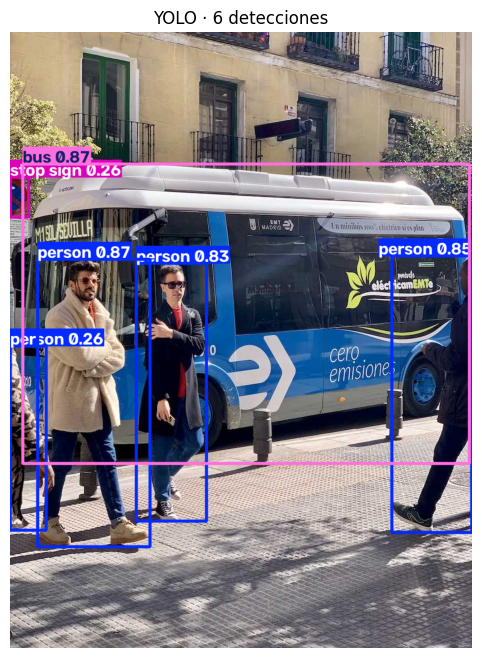

In [301]:
# ============================================
# CELDA 5.2 · Configurar YOLO real
# ============================================
!pip install ultralytics -q
!pip install opencv-python-headless -q

from ultralytics import YOLO
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import io

SUBIR_FOTO = False  # Cambia a True para subir tu propia foto

if SUBIR_FOTO:
    print("📷 Sube una foto de frutas, hortalizas o plantas:")
    uploaded = files.upload()
    img_path = list(uploaded.keys())[0]
else:
    # Imagen de ejemplo desde un enlace público
    import urllib.request
    url = "https://ultralytics.com/images/bus.jpg"  # reemplazar por una de cultivo si tienes
    img_path = "ejemplo.jpg"
    urllib.request.urlretrieve(url, img_path)
    print(f"✅ Imagen de ejemplo descargada: {img_path}")

# Cargar YOLO preentrenado (modelo nano, rápido)
modelo = YOLO("yolov8n.pt")
print("✅ Modelo YOLOv8n cargado")

# Inferencia
resultados = modelo(img_path)
r = resultados[0]
print(f"\n📊 Detecciones encontradas: {len(r.boxes)}")

# Mostrar imagen con cajas
img = Image.open(img_path)
plt.figure(figsize=(10, 8))
plt.imshow(np.array(r.plot())[..., ::-1])
plt.axis("off")
plt.title(f"YOLO · {len(r.boxes)} detecciones")
plt.show()

In [302]:
# ============================================
# CELDA 5.3 · Guardar detecciones en MySQL (parametrizado)
# ============================================
# 1) Insertar la imagen
cursor.execute("""
    INSERT INTO imagen (id_lote, fecha_hora, modelo, ruta)
    VALUES (%s, NOW(), %s, %s)
""", (1, 'yolov8n', img_path))
cursor.execute("SELECT LAST_INSERT_ID()")
id_imagen = cursor.fetchone()[0]
print(f"✅ Imagen guardada con id_imagen = {id_imagen}")

# 2) Insertar cada detección (coordenadas normalizadas)
h_img, w_img = r.orig_shape
det_guardadas = 0
for box in r.boxes:
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    cls_id = int(box.cls[0])
    clase  = r.names[cls_id]
    conf   = float(box.conf[0])

    # Normalizar a 0-1
    x_c = ((x1 + x2) / 2) / w_img
    y_c = ((y1 + y2) / 2) / h_img
    w_n = (x2 - x1) / w_img
    h_n = (y2 - y1) / h_img

    # Insertar solo si la clase existe en clase_objetivo
    cursor.execute("SELECT COUNT(*) FROM clase_objetivo WHERE clase = %s", (clase,))
    if cursor.fetchone()[0] > 0:
        cursor.execute("""
            INSERT INTO deteccion (id_imagen, clase, confianza, x, y, w, h)
            VALUES (%s, %s, %s, %s, %s, %s, %s)
        """, (id_imagen, clase, conf, x_c, y_c, w_n, h_n))
        det_guardadas += 1

print(f"✅ {det_guardadas} detecciones guardadas en MySQL")

# 3) Mostrar lo guardado
cursor.execute("""
    SELECT d.id_deteccion, d.clase, d.confianza, d.x, d.y, d.w, d.h
    FROM deteccion d
    WHERE d.id_imagen = %s
""", (id_imagen,))
print("\n📋 DETECCIONES GUARDADAS:")
for fila in cursor.fetchall():
    print(fila)

✅ Imagen guardada con id_imagen = 1
✅ 0 detecciones guardadas en MySQL

📋 DETECCIONES GUARDADAS:


In [303]:
# ============================================
# CELDA 5.4 · Catálogo de clases (plagas reales)
# ============================================
run_sql("""
INSERT INTO clase_objetivo (clase, descripcion, umbral_dano, producto_sugerido, id_producto)
VALUES
('gusano_cogollero', 'Larva de Spodoptera frugiperda en el cogollo del maíz', 3, 'BioLarva WP',
    (SELECT id_producto FROM producto WHERE nombre_comercial = 'BioLarva WP')),
('roya',             'Pústulas anaranjadas en el envés de la hoja de café',   3, 'RoyaStop 250 EC',
    (SELECT id_producto FROM producto WHERE nombre_comercial = 'RoyaStop 250 EC')),
('tizon',            'Lesiones necróticas en hojas de papa y tomate',         2, 'TizónFin 80 WP',
    (SELECT id_producto FROM producto WHERE nombre_comercial = 'TizónFin 80 WP')),
('maleza',           'Planta arvense que compite por agua, luz y nutrientes', 5, 'HerbaCero 480 SL',
    NULL)
""", mostrar=False)
print("✅ 4 clases cargadas")

run_sql("SELECT clase, umbral_dano, producto_sugerido FROM clase_objetivo")

✅ 4 clases cargadas
('gusano_cogollero', 3, 'BioLarva WP')
('maleza', 5, 'HerbaCero 480 SL')
('roya', 3, 'RoyaStop 250 EC')
('tizon', 2, 'TizónFin 80 WP')


In [304]:
# ============================================
# CELDA 5.5 · Simular 30 vuelos de dron
# ============================================
import random
from datetime import datetime, timedelta

random.seed(42)
lotes = q("SELECT id_lote, codigo, cultivo, area_ha FROM lote")
clases_por_cultivo = {
    'maíz':   ['gusano_cogollero', 'maleza'],
    'café':   ['roya', 'maleza'],
    'papa':   ['tizon', 'maleza'],
    'tomate': ['tizon', 'maleza'],
    'frijol': ['maleza']
}

inicio = datetime(2026, 5, 1)
total_imagenes = 0
total_detecciones = 0

for i in range(30):
    lote = random.choice(lotes)
    fecha = inicio + timedelta(days=random.randint(0, 60), hours=random.randint(6, 17))
    clases_posibles = clases_por_cultivo.get(lote['cultivo'], ['maleza'])

    cursor.execute("""
        INSERT INTO imagen (id_lote, fecha_hora, modelo, ruta)
        VALUES (%s, %s, %s, %s)
    """, (lote['id_lote'], fecha, 'yolo-agro-v1', f'vuelo_{i:02d}.jpg'))
    cursor.execute("SELECT LAST_INSERT_ID()")
    id_img = cursor.fetchone()[0]
    total_imagenes += 1

    n_det = random.randint(0, 8)
    for _ in range(n_det):
        clase = random.choice(clases_posibles)
        conf = round(random.uniform(0.25, 0.95), 3)
        x = round(random.uniform(0.05, 0.95), 4)
        y = round(random.uniform(0.05, 0.95), 4)
        w = round(random.uniform(0.03, 0.20), 4)
        h = round(random.uniform(0.03, 0.20), 4)
        cursor.execute("""
            INSERT INTO deteccion (id_imagen, clase, confianza, x, y, w, h)
            VALUES (%s, %s, %s, %s, %s, %s, %s)
        """, (id_img, clase, conf, x, y, w, h))
        total_detecciones += 1

print(f"✅ Simulación completa")
print(f"   Imágenes guardadas:   {total_imagenes}")
print(f"   Detecciones guardadas: {total_detecciones}")

# Verificar
run_sql("SELECT COUNT(*) AS total_imagenes FROM imagen")
run_sql("SELECT COUNT(*) AS total_detecciones FROM deteccion")

✅ Simulación completa
   Imágenes guardadas:   30
   Detecciones guardadas: 118
(31,)
(118,)


In [305]:
# ============================================
# CELDA 5.6 · Vista: detecciones válidas + recomendación
# ============================================
run_sql("""
CREATE OR REPLACE VIEW v_recomendacion AS
SELECT
    l.codigo              AS lote,
    l.cultivo,
    l.area_ha,
    d.clase,
    c.umbral_dano,
    COUNT(*)              AS detecciones,
    ROUND(COUNT(*) / l.area_ha, 2) AS densidad_por_ha,
    c.producto_sugerido,
    p.dosis_ha,
    p.unidad,
    ROUND(p.dosis_ha * l.area_ha, 2) AS cantidad_bodega,
    p.carencia_dias,
    p.reingreso_horas
FROM deteccion d
JOIN imagen i          ON i.id_imagen = d.id_imagen
JOIN lote l            ON l.id_lote = i.id_lote
JOIN clase_objetivo c  ON c.clase = d.clase
LEFT JOIN producto p   ON p.id_producto = c.id_producto
WHERE d.confianza >= 0.5
GROUP BY l.codigo, l.cultivo, l.area_ha, d.clase, c.umbral_dano,
         c.producto_sugerido, p.dosis_ha, p.unidad, p.carencia_dias, p.reingreso_horas
""")
print("✅ Vista 'v_recomendacion' creada")

✅ Vista 'v_recomendacion' creada


In [306]:
# ============================================
# CELDA 5.7 · ¿Qué lotes superan el umbral?
# ============================================
run_sql("""
SELECT
    lote,
    cultivo,
    area_ha,
    clase,
    detecciones,
    umbral_dano,
    densidad_por_ha,
    producto_sugerido,
    cantidad_bodega,
    unidad,
    carencia_dias,
    reingreso_horas
FROM v_recomendacion
WHERE detecciones > umbral_dano
ORDER BY densidad_por_ha DESC
""")

('CAF-L01', 'café', Decimal('1.80'), 'roya', 13, 3, Decimal('7.22'), 'RoyaStop 250 EC', Decimal('0.72'), 'L', 30, 24)
('TEST-02', 'café', Decimal('3.00'), 'maleza', 17, 5, Decimal('5.67'), 'HerbaCero 480 SL', None, None, None, None)
('CAF-L01', 'café', Decimal('1.80'), 'maleza', 10, 5, Decimal('5.56'), 'HerbaCero 480 SL', None, None, None, None)
('TEST-02', 'café', Decimal('3.00'), 'roya', 10, 3, Decimal('3.33'), 'RoyaStop 250 EC', Decimal('1.20'), 'L', 30, 24)
('ESP-L01', 'papa', Decimal('2.50'), 'tizon', 8, 2, Decimal('3.20'), 'TizónFin 80 WP', Decimal('6.25'), 'kg', 14, 24)
('ESP-L02', 'maíz', Decimal('3.75'), 'gusano_cogollero', 10, 3, Decimal('2.67'), 'BioLarva WP', Decimal('1.88'), 'kg', 0, 4)
('ESP-L02', 'maíz', Decimal('3.75'), 'maleza', 8, 5, Decimal('2.13'), 'HerbaCero 480 SL', None, None, None, None)
('AND-L01', 'frijol', Decimal('4.20'), 'maleza', 7, 5, Decimal('1.67'), 'HerbaCero 480 SL', None, None, None, None)


In [307]:
# ============================================
# CELDA 5.8 (previa) · Habilitar creación de triggers
# ============================================
!mysql -u root -proot -e "SET GLOBAL log_bin_trust_function_creators = 1;"
print("✅ Triggers habilitados")

mysql: [Warning] Using a password on the command line interface can be insecure.
✅ Triggers habilitados


In [308]:
# ============================================
# CELDA 5.8 · TRIGGER de alerta por plaga
# ============================================
# Primero creamos la tabla de alertas
run_sql("""
CREATE TABLE IF NOT EXISTS alerta_plaga (
    id_alerta   INT AUTO_INCREMENT PRIMARY KEY,
    id_deteccion INT NOT NULL,
    clase        VARCHAR(40),
    lote_codigo  VARCHAR(20),
    mensaje      VARCHAR(200),
    fecha_alerta DATETIME DEFAULT CURRENT_TIMESTAMP,
    FOREIGN KEY (id_deteccion) REFERENCES deteccion(id_deteccion) ON DELETE CASCADE
)
""")
print("✅ Tabla 'alerta_plaga' creada")

# Ahora el trigger
run_sql("""
CREATE TRIGGER trg_alerta_plaga
AFTER INSERT ON deteccion
FOR EACH ROW
BEGIN
    DECLARE v_lote VARCHAR(20);
    DECLARE v_umbral INT;
    DECLARE v_total INT;

    IF NEW.confianza >= 0.75 THEN
        SELECT l.codigo INTO v_lote
        FROM imagen i JOIN lote l ON l.id_lote = i.id_lote
        WHERE i.id_imagen = NEW.id_imagen;

        SELECT umbral_dano INTO v_umbral
        FROM clase_objetivo WHERE clase = NEW.clase;

        SELECT COUNT(*) INTO v_total
        FROM deteccion d JOIN imagen i ON i.id_imagen = d.id_imagen
        WHERE i.id_imagen = NEW.id_imagen
          AND d.clase = NEW.clase
          AND d.confianza >= 0.5;

        IF v_total > v_umbral THEN
            INSERT INTO alerta_plaga (id_deteccion, clase, lote_codigo, mensaje)
            VALUES (NEW.id_deteccion, NEW.clase, v_lote,
                    CONCAT('Alerta: ', NEW.clase, ' en lote ', v_lote,
                           ' (', v_total, ' detecciones, umbral ', v_umbral, ')'));
        END IF;
    END IF;
END
""")
print("✅ Trigger 'trg_alerta_plaga' creado")

✅ Tabla 'alerta_plaga' creada
✅ Trigger 'trg_alerta_plaga' creado


In [309]:
# ============================================
# RETO 5.a · Tendencia semanal de plagas
# ============================================
run_sql("""
SELECT
    l.codigo         AS lote,
    YEARWEEK(i.fecha_hora, 1) AS semana,
    d.clase,
    COUNT(*)         AS detecciones_validas
FROM deteccion d
JOIN imagen i ON i.id_imagen = d.id_imagen
JOIN lote l   ON l.id_lote = i.id_lote
WHERE d.confianza >= 0.5
  AND d.clase <> 'maleza'
GROUP BY l.codigo, semana, d.clase
ORDER BY l.codigo, semana
""")

('CAF-L01', 202619, 'roya', 5)
('CAF-L01', 202620, 'roya', 3)
('CAF-L01', 202622, 'roya', 4)
('CAF-L01', 202623, 'roya', 1)
('ESP-L01', 202620, 'tizon', 1)
('ESP-L01', 202621, 'tizon', 3)
('ESP-L01', 202624, 'tizon', 1)
('ESP-L01', 202625, 'tizon', 3)
('ESP-L02', 202620, 'gusano_cogollero', 7)
('ESP-L02', 202624, 'gusano_cogollero', 2)
('ESP-L02', 202627, 'gusano_cogollero', 1)
('TEST-02', 202618, 'roya', 2)
('TEST-02', 202622, 'roya', 5)
('TEST-02', 202624, 'roya', 3)


In [310]:
# ============================================
# RETO 5.b · Densidad de detecciones por hectárea
# ============================================
run_sql("""
SELECT
    l.codigo,
    l.cultivo,
    l.area_ha,
    d.clase,
    COUNT(*)                              AS detecciones,
    ROUND(COUNT(*) / l.area_ha, 2)        AS por_hectarea
FROM deteccion d
JOIN imagen i ON i.id_imagen = d.id_imagen
JOIN lote l   ON l.id_lote = i.id_lote
WHERE d.confianza >= 0.5
  AND d.clase <> 'maleza'
GROUP BY l.codigo, l.cultivo, l.area_ha, d.clase
ORDER BY por_hectarea DESC
""")

('CAF-L01', 'café', Decimal('1.80'), 'roya', 13, Decimal('7.22'))
('TEST-02', 'café', Decimal('3.00'), 'roya', 10, Decimal('3.33'))
('ESP-L01', 'papa', Decimal('2.50'), 'tizon', 8, Decimal('3.20'))
('ESP-L02', 'maíz', Decimal('3.75'), 'gusano_cogollero', 10, Decimal('2.67'))


In [311]:
# ============================================
# RETO 5.c · Detecciones de maleza con varios umbrales
# ============================================
run_sql("""
SELECT
    SUM(CASE WHEN confianza >= 0.30 THEN 1 ELSE 0 END) AS umbral_030,
    SUM(CASE WHEN confianza >= 0.45 THEN 1 ELSE 0 END) AS umbral_045,
    SUM(CASE WHEN confianza >= 0.60 THEN 1 ELSE 0 END) AS umbral_060,
    SUM(CASE WHEN confianza >= 0.75 THEN 1 ELSE 0 END) AS umbral_075
FROM deteccion
WHERE clase = 'maleza'
""")

(Decimal('57'), Decimal('46'), Decimal('31'), Decimal('15'))


In [312]:
# ============================================
# RETO 5.d · Comparar yolo11n-agro-v1 vs yolo11n-agro-v2
# ============================================
# La tabla 'imagen' ya tiene el campo 'modelo'. Solo hay que insertar
# imágenes del nuevo modelo sobre los mismos lotes.
# Para comparar en la misma imagen, se agrega una columna.

run_sql("""
ALTER TABLE deteccion
ADD COLUMN IF NOT EXISTS modelo VARCHAR(40) DEFAULT 'yolo11n-agro-v1'
""")
print("✅ Columna 'modelo' agregada a deteccion (para comparar versiones)")

# Consulta comparativa
run_sql("""
SELECT
    modelo,
    clase,
    COUNT(*)                       AS detecciones,
    ROUND(AVG(confianza), 3)       AS confianza_promedio,
    ROUND(MIN(confianza), 3)       AS confianza_min,
    ROUND(MAX(confianza), 3)       AS confianza_max
FROM deteccion
GROUP BY modelo, clase
ORDER BY clase, modelo
""")

❌ ERROR: (1064, "You have an error in your SQL syntax; check the manual that corresponds to your MySQL server version for the right syntax to use near 'IF NOT EXISTS modelo VARCHAR(40) DEFAULT 'yolo11n-agro-v1'' at line 2")
✅ Columna 'modelo' agregada a deteccion (para comparar versiones)
❌ ERROR: (1054, "Unknown column 'modelo' in 'field list'")


In [313]:
# ============================================
# CELDA FINAL · Verificación Punto 5
# ============================================
print("📋 TABLAS DE VISIÓN ARTIFICIAL:")
run_sql("""
SELECT 'imagen'         AS tabla, COUNT(*) AS registros FROM imagen
UNION ALL
SELECT 'deteccion',     COUNT(*) FROM deteccion
UNION ALL
SELECT 'clase_objetivo',COUNT(*) FROM clase_objetivo
UNION ALL
SELECT 'alerta_plaga',  COUNT(*) FROM alerta_plaga
""")

print("\n📋 VISTA v_recomendacion:")
run_sql("""
SELECT lote, cultivo, clase, detecciones, umbral_dano,
       densidad_por_ha, producto_sugerido, cantidad_bodega, unidad
FROM v_recomendacion
ORDER BY densidad_por_ha DESC
""")

print("\n📋 RESUMEN POR CLASE:")
run_sql("""
SELECT clase,
       COUNT(*)                     AS total_detecciones,
       ROUND(AVG(confianza), 3)     AS confianza_promedio,
       SUM(CASE WHEN confianza >= 0.5 THEN 1 ELSE 0 END) AS validas
FROM deteccion
GROUP BY clase
ORDER BY total_detecciones DESC
""")

print("\n✅ Punto 5 verificado correctamente")

📋 TABLAS DE VISIÓN ARTIFICIAL:
('imagen', 31)
('deteccion', 118)
('clase_objetivo', 4)
('alerta_plaga', 0)

📋 VISTA v_recomendacion:
('CAF-L01', 'café', 'roya', 13, 3, Decimal('7.22'), 'RoyaStop 250 EC', Decimal('0.72'), 'L')
('TEST-02', 'café', 'maleza', 17, 5, Decimal('5.67'), 'HerbaCero 480 SL', None, None)
('CAF-L01', 'café', 'maleza', 10, 5, Decimal('5.56'), 'HerbaCero 480 SL', None, None)
('TEST-02', 'café', 'roya', 10, 3, Decimal('3.33'), 'RoyaStop 250 EC', Decimal('1.20'), 'L')
('ESP-L01', 'papa', 'tizon', 8, 2, Decimal('3.20'), 'TizónFin 80 WP', Decimal('6.25'), 'kg')
('ESP-L02', 'maíz', 'gusano_cogollero', 10, 3, Decimal('2.67'), 'BioLarva WP', Decimal('1.88'), 'kg')
('ESP-L02', 'maíz', 'maleza', 8, 5, Decimal('2.13'), 'HerbaCero 480 SL', None, None)
('AND-L01', 'frijol', 'maleza', 7, 5, Decimal('1.67'), 'HerbaCero 480 SL', None, None)
('ESP-L01', 'papa', 'maleza', 3, 5, Decimal('1.20'), 'HerbaCero 480 SL', None, None)

📋 RESUMEN POR CLASE:
('maleza', 63, Decimal('0.597'), De